In [1]:
import pandas as pd
import numpy as np
import os
import subprocess
from matplotlib import pyplot as plt
from urllib.request import urlretrieve

In [2]:
if not os.path.isfile("../data/raw/imoex_daily.csv"):
    subprocess.run(
        [
            "uv", "run",
            "--group", "data",
            "python", "../scripts/download_imoex.py",
        ],
        check=True,
    )

imoex = pd.read_csv(
    "../data/raw/imoex_daily.csv",
    parse_dates=["trade_date"],
)

imoex.head()

,trade_date,index_code,close
0,2018-01-03,IMOEX,2152.97
1,2018-01-04,IMOEX,2197.60
2,2018-01-05,IMOEX,2207.41
3,2018-01-09,IMOEX,2225.39
4,2018-01-10,IMOEX,2232.27


In [3]:
quality = pd.Series({
    "Количество строк": len(imoex),
    "Первая дата": imoex["trade_date"].min().date(),
    "Последняя дата": imoex["trade_date"].max().date(),
    "Коды индекса": imoex["index_code"].unique().tolist(),
    "Пропуски в датах": imoex["trade_date"].isna().sum(),
    "Пропуски в кодах": imoex["index_code"].isna().sum(),
    "Пропуски в закрытиях": imoex["close"].isna().sum(),
    "Дубли по дате и индексу": imoex.duplicated(
        subset=["trade_date", "index_code"]
    ).sum(),
    "Даты по возрастанию": imoex["trade_date"].is_monotonic_increasing,
    "Неположительные закрытия": (imoex["close"] <= 0).sum(),
})

quality

Количество строк                  2222
Первая дата                 2018-01-03
Последняя дата              2026-11-02
Коды индекса                   [IMOEX]
Пропуски в датах                     0
Пропуски в кодах                     0
Пропуски в закрытиях                 0
Дубли по дате и индексу              0
Даты по возрастанию               True
Неположительные закрытия             0
dtype: object

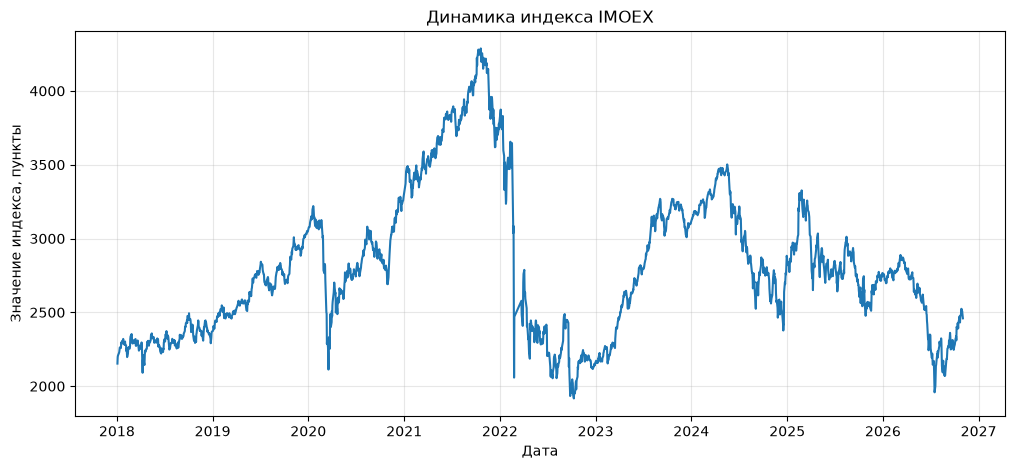

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(imoex["trade_date"], imoex["close"])

ax.set_title("Динамика индекса IMOEX")
ax.set_xlabel("Дата")
ax.set_ylabel("Значение индекса, пункты")
ax.grid(alpha=0.3)

plt.show()

Произошел обвал индекса в феврале 2022 года

In [5]:
imoex["imoex_ret_1d"] = np.log(
    imoex["close"] / imoex["close"].shift(1)
)

In [6]:
date_gaps = pd.DataFrame({
    "previous_date": imoex["trade_date"].shift(1),
    "trade_date": imoex["trade_date"],
    "gap_days": imoex["trade_date"].diff().dt.days,
})

date_gaps.nlargest(5, "gap_days")

,previous_date,trade_date,gap_days
1050,2022-02-25,2022-03-24,27.0
2010,2025-12-30,2026-01-05,6.0
254,2018-12-29,2019-01-03,5.0
756,2020-12-30,2021-01-04,5.0
1077,2022-04-29,2022-05-04,5.0


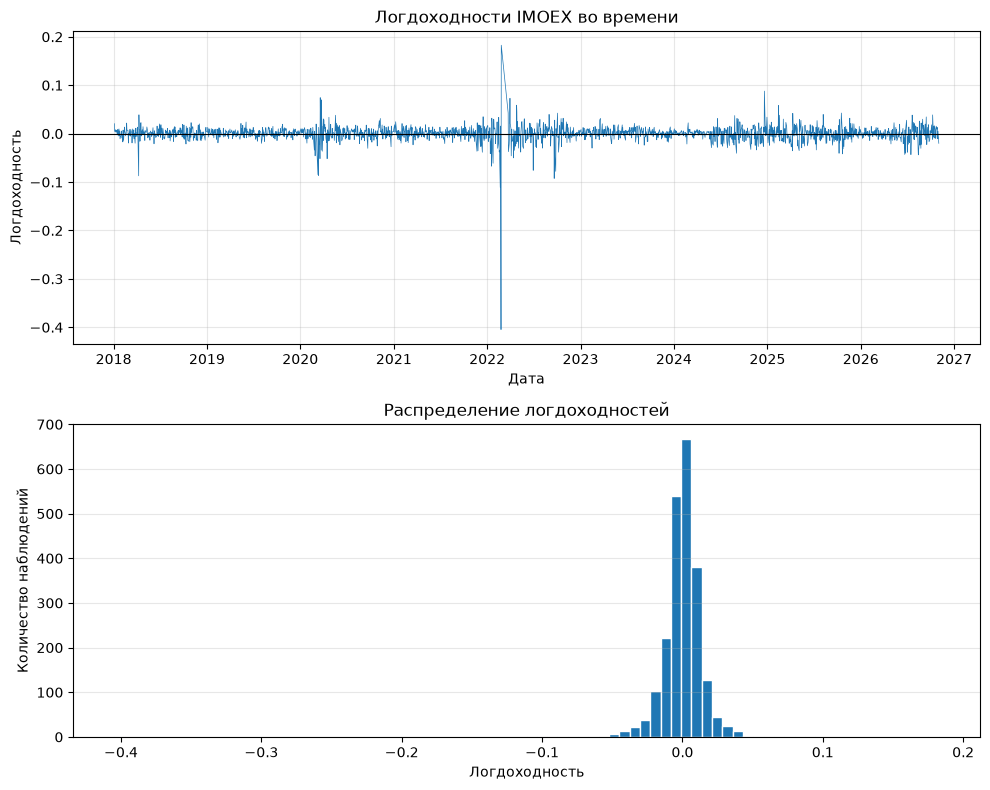

In [7]:
returns = imoex["imoex_ret_1d"].dropna()

fig, (ax_time, ax_hist) = plt.subplots(2, 1, figsize=(10, 8))

ax_time.plot(
    imoex["trade_date"],
    imoex["imoex_ret_1d"],
    linewidth=0.5,
)
ax_time.axhline(0, color="black", linewidth=0.8)
ax_time.set_title("Логдоходности IMOEX во времени")
ax_time.set_xlabel("Дата")
ax_time.set_ylabel("Логдоходность")
ax_time.grid(alpha=0.3)

ax_hist.hist(returns, bins=80, edgecolor="white")
ax_hist.set_title("Распределение логдоходностей")
ax_hist.set_xlabel("Логдоходность")
ax_hist.set_ylabel("Количество наблюдений")
ax_hist.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
columns = ["trade_date", "close", "imoex_ret_1d"]

display(imoex.nsmallest(5, "imoex_ret_1d")[columns])
display(imoex.nlargest(5, "imoex_ret_1d")[columns])

,trade_date,close,imoex_ret_1d
1048,2022-02-24,2058.12,-0.404674
1046,2022-02-21,3036.88,-0.110975
1173,2022-09-20,2215.67,-0.092559
65,2018-04-09,2090.88,-0.087130
552,2020-03-12,2286.40,-0.086460


,trade_date,close,imoex_ret_1d
1049,2022-02-25,2470.48,0.182620
1748,2024-12-20,2638.42,0.087881
557,2020-03-19,2275.70,0.074349
1055,2022-03-31,2703.51,0.073062
560,2020-03-24,2415.97,0.069683


In [9]:
imoex["imoex_vol_21d"] = np.sqrt(
    imoex["imoex_ret_1d"]
    .pow(2)
    .rolling(window=21, min_periods=21)
    .mean()
)

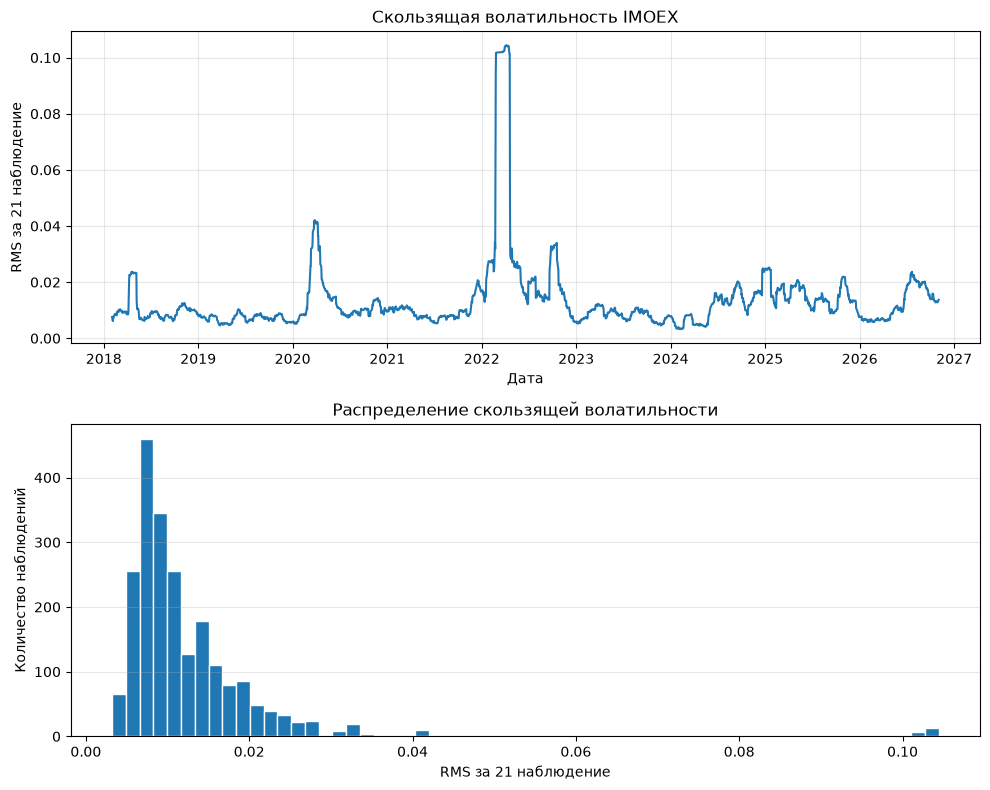

In [10]:
fig, (ax_time, ax_hist) = plt.subplots(2, 1, figsize=(10, 8))

ax_time.plot(imoex["trade_date"], imoex["imoex_vol_21d"])
ax_time.set_title("Скользящая волатильность IMOEX")
ax_time.set_xlabel("Дата")
ax_time.set_ylabel("RMS за 21 наблюдение")
ax_time.grid(alpha=0.3)

ax_hist.hist(
    imoex["imoex_vol_21d"].dropna(),
    bins=60,
    edgecolor="white",
)
ax_hist.set_title("Распределение скользящей волатильности")
ax_hist.set_xlabel("RMS за 21 наблюдение")
ax_hist.set_ylabel("Количество наблюдений")
ax_hist.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

In [11]:
imoex[["imoex_ret_1d", "imoex_vol_21d"]].describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
)

,imoex_ret_1d,imoex_vol_21d
count,2221.000000,2201.000000
mean,0.000060,0.012638
std,0.016624,0.010865
min,-0.404674,0.003209
1%,-0.040496,0.004167
5%,-0.020827,0.005316
50%,0.000789,0.009854
95%,0.019402,0.025531
99%,0.034390,0.042082
max,0.182620,0.104421


In [12]:
lags = [1, 5, 21]
extreme_dates = pd.to_datetime(["2022-02-24", "2022-02-25"])

returns_sensitivity = imoex["imoex_ret_1d"].mask(
    imoex["trade_date"].isin(extreme_dates)
)

autocorrelation = pd.DataFrame({
    "returns": [
        returns.autocorr(lag=k) for k in lags
    ],
    "absolute_returns": [
        returns.abs().autocorr(lag=k) for k in lags
    ],
    "absolute_returns_without_two_extremes": [
        returns_sensitivity.abs().autocorr(lag=k) for k in lags
    ],
}, index=lags)

autocorrelation.index.name = "lag"
autocorrelation

,returns,absolute_returns,absolute_returns_without_two_extremes
lag,,,
1,-0.070099,0.318154,0.240938
5,0.011815,0.129859,0.185697
21,-0.012877,0.102930,0.170890


1. Доходности могут быть положительными, а могут быть отрицательными, их модуль отражает размер изменения.
2. После исключения двух крайних значений (по доходности) коэффициенты изменились, но положительная связь сохранилась. Значит, она связана не только с этими наблюдениями.
3. Автокорреляция модулей доходности показала положительную взаимосвязь, поэтому мы можем исследовать возможности ее прогнозирования. Правда RMS не гарантирует падения или доходности, он описывает движение.

In [13]:
file_path = "../data/processed/prices_ix_secs.csv"

if not os.path.isfile(file_path):
    os.makedirs("../data/processed", exist_ok=True)

    url = (
        "https://www.kaggle.com/api/v1/datasets/download/"
        "andrejmaximov/moex-stock/prices_ix_secs.csv"
    )

    urlretrieve(url, file_path + ".tmp")
    os.replace(file_path + ".tmp", file_path)

full_dataset = pd.read_csv(file_path, parse_dates=["trade_date"])
full_dataset.head()

,trade_date,close_ix,boardid,ticker,open,high,low,close,volume,value,numtrades,sector,secid,open_uv,close_uv,low_uv,high_uv,value_uv
0,2018-01-03,2152.97,TQBR,AFKS,12.485,12.55,12.26,12.350,20687500,256119052.0,5071,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2018-01-03,2152.97,TQBR,AFLT,139.100,140.95,138.60,140.400,2126700,296982430.0,3163,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2018-01-03,2152.97,TQBR,ALRS,75.210,75.96,75.15,75.810,3908500,295337171.0,3719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2018-01-03,2152.97,TQBR,BSPB,54.800,54.85,54.55,54.850,8730,477857.5,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2018-01-03,2152.97,TQBR,CBOM,4.680,4.74,4.68,4.735,1065500,5039994.8,294,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
full_dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76843 entries, 0 to 76842
Data columns (total 18 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   trade_date  76843 non-null  datetime64[ns]
 1   close_ix    76843 non-null  float64       
 2   boardid     76843 non-null  object        
 3   ticker      76843 non-null  object        
 4   open        76605 non-null  float64       
 5   high        76605 non-null  float64       
 6   low         76605 non-null  float64       
 7   close       76605 non-null  float64       
 8   volume      76843 non-null  int64         
 9   value       76843 non-null  float64       
 10  numtrades   76843 non-null  int64         
 11  sector      56722 non-null  object        
 12  secid       56722 non-null  object        
 13  open_uv     56722 non-null  float64       
 14  close_uv    56722 non-null  float64       
 15  low_uv      56722 non-null  float64       
 16  high_uv     56722 non-

In [15]:
print("Первая дата:", full_dataset["trade_date"].min())
print("Последняя дата:", full_dataset["trade_date"].max())
print("Количество бумаг:", full_dataset["ticker"].nunique())
print(
    "Дубли по дате, режиму торгов и тикеру:",
    full_dataset.duplicated(
        subset=["trade_date", "boardid", "ticker"]
    ).sum(),
)

Первая дата: 2018-01-03 00:00:00
Последняя дата: 2026-11-02 00:00:00
Количество бумаг: 44
Дубли по дате, режиму торгов и тикеру: 0


In [16]:
missing_prices = full_dataset.loc[
    full_dataset["close"].isna(),
    ["trade_date", "ticker", "close", "volume", "numtrades"],
]

missing_prices.head(10)

,trade_date,ticker,close,volume,numtrades
15042,2020-02-18,ENPG,NaN,0,0
15071,2020-02-19,ENPG,NaN,0,0
19348,2020-09-22,RUAL,NaN,0,0
19377,2020-09-23,RUAL,NaN,0,0
19406,2020-09-24,RUAL,NaN,0,0
19435,2020-09-25,RUAL,NaN,0,0
28061,2021-10-20,RENI,NaN,0,0
29886,2022-01-07,AFKS,NaN,0,0
29887,2022-01-07,AFLT,NaN,0,0
29888,2022-01-07,ALRS,NaN,0,0


In [17]:
print("Всего строк без close:", len(missing_prices))
print(
    "Во всех строках объём и число сделок равны нулю:",
    (
        (missing_prices["volume"] == 0)
        & (missing_prices["numtrades"] == 0)
    ).all(),
)

Всего строк без close: 238
Во всех строках объём и число сделок равны нулю: True


In [18]:
features = ["imoex_ret_1d", "imoex_vol_21d"]

missing_features = [
    column for column in features
    if column not in full_dataset.columns
]

if missing_features:
    full_dataset = full_dataset.merge(
        imoex[["trade_date"] + missing_features],
        on="trade_date",
        how="left",
        validate="many_to_one",
    )

full_dataset.shape

(76843, 20)

In [19]:
coverage = full_dataset.groupby("ticker").agg(
    first_date=("trade_date", "min"),
    last_date=("trade_date", "max"),
    observations=("trade_date", "nunique"),
)

coverage.sort_values("first_date", ascending=False).head(10)

,first_date,last_date,observations
ticker,,,
DOMRF,2025-11-20,2026-11-02,241
RAGR,2025-02-17,2026-11-02,436
CNRU,2025-02-07,2026-11-02,442
X5,2025-01-09,2026-11-02,463
T,2024-11-28,2026-11-02,490
HEAD,2024-08-16,2026-11-02,564
YDEX,2024-07-08,2026-11-02,593
SVCB,2023-12-15,2026-11-02,733
UGLD,2023-11-22,2026-11-02,750


In [20]:
calendar_rows = []

for ticker, stock in full_dataset.groupby("ticker"):
    index_dates = imoex.loc[
        imoex["trade_date"].between(
            stock["trade_date"].min(),
            stock["trade_date"].max(),
        ),
        "trade_date",
    ]

    calendar_rows.append({
        "ticker": ticker,
        "missing_dates": (~index_dates.isin(stock["trade_date"])).sum(),
        "dates_outside_imoex": (
            ~stock["trade_date"].isin(imoex["trade_date"])
        ).sum(),
    })

calendar_check = pd.DataFrame(calendar_rows).set_index("ticker")
calendar_check.sort_values("missing_dates", ascending=False).head(10)

,missing_dates,dates_outside_imoex
ticker,,
AFKS,0,0
AFLT,0,0
POSI,0,0
RAGR,0,0
RENI,0,0
ROSN,0,0
RTKM,0,0
RUAL,0,0
SBER,0,0
